# Practical 3 — 0/1 Knapsack using Dynamic Programming and Branch & Bound

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Write a program to solve the **0/1 Knapsack problem** using dynamic
programming and branch-and-bound strategies.

## 2. Problem statement

Given $n$ items, where item $i$ has weight $w_i$ and value $v_i$, and a
knapsack of capacity $W$, choose a subset of items such that:

$$\max \sum_{i \in S} v_i \quad\text{subject to}\quad \sum_{i \in S} w_i \le W,
\qquad S \subseteq \{1,\dots,n\}.$$

Each item is either taken completely (1) or not taken at all (0). An item
cannot be split; that is what distinguishes 0/1 knapsack from **fractional
knapsack**, which is solved greedily.

## 3. Objectives

- Understand overlapping sub-problems and optimal substructure.
- Implement bottom-up tabulation, top-down memoisation and a
  branch-and-bound search.
- Reconstruct the set of selected items, not just the optimal value.
- Compare the time and space requirements of the approaches.

## 4. Theory

### 4.1 Optimal substructure

Let $T(i, c)$ be the maximum value obtainable using the first $i$ items with
capacity $c$. Then:

$$T(i,c)=
\begin{cases}
0, & i=0 \text{ or } c=0,\\[2mm]
T(i-1,c), & w_i > c,\\[2mm]
\max\bigl(T(i-1,c),\ v_i + T(i-1,c-w_i)\bigr), & w_i \le c.
\end{cases}$$

The two choices are **skip item $i$** or **take item $i$**. The table has
$(n+1)(W+1)$ cells, so the running time is $O(nW)$ and the space is $O(nW)$.

Because $W$ is a number, not the number of input bits, this is called a
**pseudo-polynomial** algorithm. It is efficient when $W$ is moderate.

### 4.2 Reconstructing the solution

Start at $T(n,W)$. If $T(i,c) \ne T(i-1,c)$, item $i$ was taken; move to
$(i-1, c-w_i)$. Otherwise item $i$ was skipped; move to $(i-1,c)$.

### 4.3 Branch and bound

Branch and bound explores a search tree of include/exclude decisions. At each
node it computes an **upper bound** on the best value that can still be
obtained. If the bound is not better than the best complete solution found so
far, the whole subtree is pruned.

A common bound is the **fractional knapsack bound**: sort remaining items by
value/weight and fill the remaining capacity as if fractions were allowed.
This is an optimistic (over-)estimate, so it is safe for pruning.

### 4.4 Complexity

| Method | Time | Space | Notes |
|---|---|---|---|
| Tabulation | $O(nW)$ | $O(nW)$ | Always fills the whole table |
| Memoisation | $O(nW)$ | $O(nW)$ | Only reachable states |
| 1-D DP | $O(nW)$ | $O(W)$ | Value only; reconstruction needs extra data |
| Branch and bound | $O(2^n)$ worst | $O(n)$—$O(2^n)$ | Often much faster due to pruning |

In [1]:
from functools import lru_cache
import heapq
from time import perf_counter

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Test instance used throughout the notebook.
item_names = ["A", "B", "C", "D", "E"]
weights = [2, 3, 4, 5, 9]
values = [3, 4, 5, 8, 10]
capacity = 10

items_table = pd.DataFrame(
    {
        "item": item_names,
        "weight": weights,
        "value": values,
        "value/weight": [round(v / w, 2) for v, w in zip(values, weights)],
    }
)
items_table

,item,weight,value,value/weight
0,A,2,3,1.50
1,B,3,4,1.33
2,C,4,5,1.25
3,D,5,8,1.60
4,E,9,10,1.11


In [3]:
def knapsack_tabulation(weights, values, capacity):
    """Bottom-up 0/1 knapsack.

    Returns (best_value, chosen_indices, table), where table is the full
    (n+1) x (capacity+1) DP table.
    """
    if capacity < 0:
        raise ValueError("capacity must be non-negative")
    if len(weights) != len(values):
        raise ValueError("weights and values must have the same length")
    if any(w < 0 for w in weights):
        raise ValueError("weights must be non-negative")

    n = len(weights)
    table = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        item_weight = weights[i - 1]
        item_value = values[i - 1]
        for c in range(capacity + 1):
            # Do not take item i.
            table[i][c] = table[i - 1][c]
            # Take item i if it fits and improves the value.
            if item_weight <= c:
                take = item_value + table[i - 1][c - item_weight]
                if take > table[i][c]:
                    table[i][c] = take

    # Reconstruct the chosen items by walking backwards through the table.
    chosen = []
    c = capacity
    for i in range(n, 0, -1):
        if table[i][c] != table[i - 1][c]:
            chosen.append(i - 1)
            c -= weights[i - 1]
    chosen.reverse()

    return table[n][capacity], chosen, table


best_value, chosen, dp_table = knapsack_tabulation(weights, values, capacity)

print("Optimal value :", best_value)
print("Chosen items  :", [item_names[i] for i in chosen])
print("Total weight  :", sum(weights[i] for i in chosen))

Optimal value : 15
Chosen items  : ['A', 'B', 'D']
Total weight  : 10


In [4]:
# Display the DP table. Rows are the number of items considered; columns are
# capacities from 0 to W.
dp_display = pd.DataFrame(
    dp_table,
    index=["no items"] + [f"+ {name} (w={w})" for name, w in zip(item_names, weights)],
    columns=[f"c={c}" for c in range(capacity + 1)],
)
dp_display

,c=0,c=1,c=2,c=3,c=4,c=5,c=6,c=7,c=8,c=9,c=10
no items,0,0,0,0,0,0,0,0,0,0,0
+ A (w=2),0,0,3,3,3,3,3,3,3,3,3
+ B (w=3),0,0,3,4,4,7,7,7,7,7,7
+ C (w=4),0,0,3,4,5,7,8,9,9,12,12
+ D (w=5),0,0,3,4,5,8,8,11,12,13,15
+ E (w=9),0,0,3,4,5,8,8,11,12,13,15


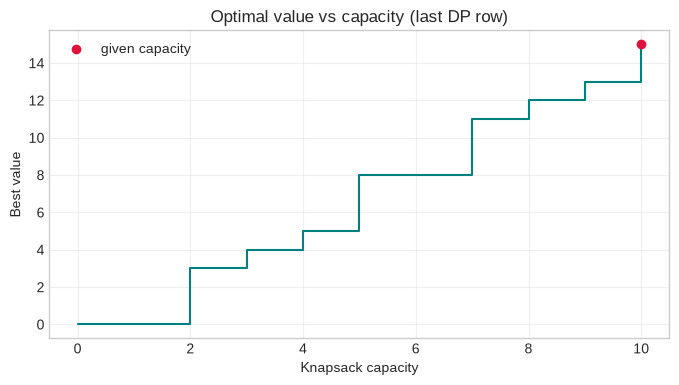

In [5]:
# The last row of the table is the optimal value as a function of capacity.
# It is non-decreasing: more capacity can never reduce the best value.
plt.figure(figsize=(8, 4))
plt.step(range(capacity + 1), dp_table[-1], where="post", color="teal")
plt.scatter([capacity], [best_value], color="crimson", zorder=3, label="given capacity")
plt.xlabel("Knapsack capacity")
plt.ylabel("Best value")
plt.title("Optimal value vs capacity (last DP row)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Top-down memoisation

The recursive definition has only $O(nW)$ distinct states. A cache avoids
recomputing a state that has already been solved.

In [6]:
def knapsack_memoisation(weights, values, capacity):
    """Top-down 0/1 knapsack with memoisation and solution reconstruction."""
    n = len(weights)

    @lru_cache(maxsize=None)
    def best(i, remaining):
        if i == 0 or remaining == 0:
            return 0
        item_weight = weights[i - 1]
        item_value = values[i - 1]
        skip = best(i - 1, remaining)
        if item_weight > remaining:
            return skip
        take = item_value + best(i - 1, remaining - item_weight)
        return max(skip, take)

    # Reconstruct by asking, at each state, which choice produced the value.
    chosen = []
    remaining = capacity
    for i in range(n, 0, -1):
        if best(i, remaining) != best(i - 1, remaining):
            chosen.append(i - 1)
            remaining -= weights[i - 1]
    chosen.reverse()

    return best(n, capacity), chosen, best.cache_info()


memo_value, memo_chosen, cache_info = knapsack_memoisation(weights, values, capacity)
print("Memoised optimal value:", memo_value)
print("Chosen items          :", [item_names[i] for i in memo_chosen])
print("Cache statistics      :", cache_info)

assert memo_value == best_value
assert memo_chosen == chosen
print("\nTabulation and memoisation agree ✓")

Memoised optimal value: 15
Chosen items          : ['A', 'B', 'D']
Cache statistics      : CacheInfo(hits=14, misses=27, maxsize=None, currsize=27)

Tabulation and memoisation agree ✓


### Space-optimised 1-D DP

Row $i$ depends only on row $i-1$. If we only need the optimal **value**, one
array of size $W+1$ is enough. The capacity loop must run **backwards**;
otherwise an item could be used more than once (which would solve the
*unbounded* knapsack problem instead).

In [7]:
def knapsack_1d(weights, values, capacity):
    """0/1 knapsack using O(W) extra space (value only)."""
    dp = [0] * (capacity + 1)
    for item_weight, item_value in zip(weights, values):
        for c in range(capacity, item_weight - 1, -1):
            dp[c] = max(dp[c], item_value + dp[c - item_weight])
    return dp[capacity]


value_1d = knapsack_1d(weights, values, capacity)
print("1-D DP optimal value:", value_1d)
assert value_1d == best_value

1-D DP optimal value: 15


### Branch-and-bound solution

Items are sorted by value/weight. A node stores the level, current profit,
current weight and the chosen indices. The priority queue always expands the
node with the highest optimistic bound. Nodes whose bound cannot beat the best
known solution are pruned.

In [8]:
def knapsack_branch_and_bound(weights, values, capacity):
    """Best-first branch and bound for 0/1 knapsack.

    Returns (best_value, chosen_indices, nodes_explored).
    """
    if capacity < 0:
        raise ValueError("capacity must be non-negative")

    n = len(weights)
    # Sort by decreasing value density; keep the original indices.
    order = sorted(range(n), key=lambda i: values[i] / weights[i], reverse=True)
    sorted_weights = [weights[i] for i in order]
    sorted_values = [values[i] for i in order]

    def fractional_bound(level, profit, weight):
        """Optimistic upper bound using fractional knapsack on the remainder."""
        if weight >= capacity:
            return profit
        bound = float(profit)
        remaining = capacity - weight
        for i in range(level, n):
            if sorted_weights[i] <= remaining:
                remaining -= sorted_weights[i]
                bound += sorted_values[i]
            else:
                bound += sorted_values[i] * remaining / sorted_weights[i]
                break
        return bound

    best_value = 0
    best_choice: tuple[int, ...] = ()
    nodes = 0

    # Heap entries: (-bound, level, profit, weight, chosen_positions)
    initial_bound = fractional_bound(0, 0, 0)
    heap = [(-initial_bound, 0, 0, 0, ())]

    while heap:
        negative_bound, level, profit, weight, chosen_positions = heapq.heappop(heap)
        bound = -negative_bound
        nodes += 1

        # Prune: even the optimistic bound cannot improve the best solution.
        if bound <= best_value + 1e-9:
            continue
        if level == n:
            continue

        item_weight = sorted_weights[level]
        item_value = sorted_values[level]

        # Branch 1: take the item (only if it fits).
        if weight + item_weight <= capacity:
            new_profit = profit + item_value
            new_weight = weight + item_weight
            new_choice = chosen_positions + (level,)
            if new_profit > best_value:
                best_value = new_profit
                best_choice = new_choice
            new_bound = fractional_bound(level + 1, new_profit, new_weight)
            if new_bound > best_value + 1e-9:
                heapq.heappush(
                    heap, (-new_bound, level + 1, new_profit, new_weight, new_choice)
                )

        # Branch 2: skip the item.
        skip_bound = fractional_bound(level + 1, profit, weight)
        if skip_bound > best_value + 1e-9:
            heapq.heappush(
                heap, (-skip_bound, level + 1, profit, weight, chosen_positions)
            )

    chosen_original = sorted(order[position] for position in best_choice)
    return best_value, chosen_original, nodes


bb_value, bb_chosen, nodes_explored = knapsack_branch_and_bound(
    weights, values, capacity
)
print("Branch-and-bound value:", bb_value)
print("Chosen items          :", [item_names[i] for i in bb_chosen])
print("Nodes explored        :", nodes_explored)

assert bb_value == best_value
print("\nBranch and bound agrees with DP ✓")

Branch-and-bound value: 15
Chosen items          : ['A', 'B', 'D']
Nodes explored        : 5

Branch and bound agrees with DP ✓


In [9]:
# Compare all methods on the same instance.
comparison = pd.DataFrame(
    [
        {
            "method": "Tabulation (2-D)",
            "best value": best_value,
            "selected items": ", ".join(item_names[i] for i in chosen),
            "time": "O(nW)",
            "space": "O(nW)",
        },
        {
            "method": "Memoisation",
            "best value": memo_value,
            "selected items": ", ".join(item_names[i] for i in memo_chosen),
            "time": "O(nW)",
            "space": "O(nW)",
        },
        {
            "method": "1-D DP",
            "best value": value_1d,
            "selected items": "(value only)",
            "time": "O(nW)",
            "space": "O(W)",
        },
        {
            "method": "Branch & bound",
            "best value": bb_value,
            "selected items": ", ".join(item_names[i] for i in bb_chosen),
            "time": "O(2^n) worst",
            "space": "O(2^n) worst",
        },
    ]
)
comparison

,method,best value,selected items,time,space
0,Tabulation (2-D),15,"A, B, D",O(nW),O(nW)
1,Memoisation,15,"A, B, D",O(nW),O(nW)
2,1-D DP,15,(value only),O(nW),O(W)
3,Branch & bound,15,"A, B, D",O(2^n) worst,O(2^n) worst


### Test cases and correctness checks

We compare DP and branch-and-bound on a set of small instances where the
answer can also be found by brute force. This is a strong correctness check.

In [10]:
from itertools import combinations


def brute_force(weights, values, capacity):
    """Try every subset; only usable for small n."""
    n = len(weights)
    best = 0
    best_subset = ()
    for size in range(n + 1):
        for subset in combinations(range(n), size):
            total_weight = sum(weights[i] for i in subset)
            if total_weight <= capacity:
                total_value = sum(values[i] for i in subset)
                if total_value > best:
                    best = total_value
                    best_subset = subset
    return best, best_subset


test_cases = [
    ([1], [1], 0),
    ([1], [1], 1),
    ([2, 3, 4], [3, 4, 5], 5),
    ([5, 5, 5], [10, 20, 30], 10),
    ([1, 2, 3, 4, 5], [2, 4, 6, 8, 10], 7),
    (weights, values, capacity),
]

rows = []
for case_number, (w, v, cap) in enumerate(test_cases, start=1):
    dp_value, dp_choice, _ = knapsack_tabulation(w, v, cap)
    bb_value_case, bb_choice, _ = knapsack_branch_and_bound(w, v, cap)
    brute_value, _ = brute_force(w, v, cap)
    rows.append(
        {
            "case": case_number,
            "n": len(w),
            "capacity": cap,
            "DP": dp_value,
            "B&B": bb_value_case,
            "brute force": brute_value,
            "all agree": dp_value == bb_value_case == brute_value,
        }
    )

test_results = pd.DataFrame(rows)
test_results

,case,n,capacity,DP,B&B,brute force,all agree
0,1,1,0,0,0,0,True
1,2,1,1,1,1,1,True
2,3,3,5,7,7,7,True
3,4,3,10,50,50,50,True
4,5,5,7,14,14,14,True
5,6,5,10,15,15,15,True


In [11]:
# Benchmark DP and branch-and-bound on random instances of increasing size.
import random

random.seed(42)
benchmark_rows = []

for n in [8, 12, 16, 20]:
    trial_times_dp = []
    trial_times_bb = []
    for _ in range(5):
        w = [random.randint(1, 20) for _ in range(n)]
        v = [random.randint(1, 50) for _ in range(n)]
        cap = int(0.4 * sum(w))

        start = perf_counter()
        knapsack_tabulation(w, v, cap)
        trial_times_dp.append(perf_counter() - start)

        start = perf_counter()
        knapsack_branch_and_bound(w, v, cap)
        trial_times_bb.append(perf_counter() - start)

    benchmark_rows.append(
        {
            "n": n,
            "capacity": cap,
            "DP median time (s)": sorted(trial_times_dp)[2],
            "B&B median time (s)": sorted(trial_times_bb)[2],
        }
    )

benchmark = pd.DataFrame(benchmark_rows)
benchmark

,n,capacity,DP median time (s),B&B median time (s)
0,8,29,0.000029,0.000019
1,12,44,0.000070,0.000024
2,16,66,0.000122,0.000041
3,20,89,0.000192,0.000053


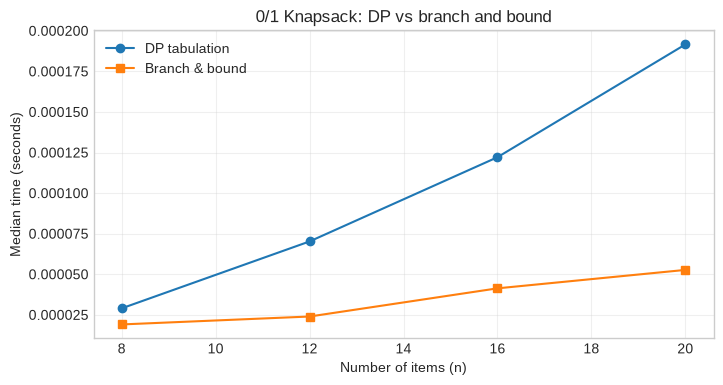

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(benchmark["n"], benchmark["DP median time (s)"], "o-", label="DP tabulation")
plt.plot(benchmark["n"], benchmark["B&B median time (s)"], "s-", label="Branch & bound")
plt.xlabel("Number of items (n)")
plt.ylabel("Median time (seconds)")
plt.title("0/1 Knapsack: DP vs branch and bound")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - DAA Practical 3 (0/1 Knapsack)")
print("=" * 78)
print(
    "The 0/1 knapsack problem chooses a subset of items. Each item is either\n"
    "taken completely or not at all, and the total weight must not exceed the\n"
    "capacity. The report below checks the optimal value, the selected items,\n"
    "the DP table, the branch-and-bound search and the benchmark."
)

chosen_names = [item_names[index] for index in chosen]
total_weight = sum(weights[index] for index in chosen)
print("\n1. PROBLEM INSTANCE")
print("-" * 78)
print(f"Items          : {item_names}")
print(f"Weights        : {weights}")
print(f"Values         : {values}")
print(f"Capacity       : {capacity}")
for name, weight, value in zip(item_names, weights, values):
    print(f"  {name}: weight={weight}, value={value}, value/weight={value / weight:.2f}")

print("\n2. OPTIMAL SOLUTION (DYNAMIC PROGRAMMING)")
print("-" * 78)
print(f"Best value     : {best_value}")
print(f"Chosen items   : {chosen_names}")
print(f"Total weight   : {total_weight} / {capacity}")
print(f"Unused capacity: {capacity - total_weight}")
print(f"DP table shape : {len(dp_table)} rows x {len(dp_table[0])} columns")
print("Interpretation: the last cell T(n, W) is the best value. The selected")
print("items are recovered by walking backwards: if T(i, c) differs from")
print("T(i-1, c), item i was taken and the remaining capacity is reduced.")
print("Every chosen item is included at most once; this is the 0/1 rule.")

print("\n3. TOP-DOWN MEMOISATION")
print("-" * 78)
print(f"Memoised value : {memo_value}")
print(f"Chosen items   : {[item_names[index] for index in memo_chosen]}")
print(f"Cache hits     : {cache_info.hits}")
print(f"Cache misses   : {cache_info.misses}")
print(f"Cached states  : {cache_info.currsize}")
print("The memoised result matches tabulation. Cache hits are states that were")
print("needed more than once; they represent work that naive recursion would")
print("have repeated.")

print("\n4. SPACE-OPTIMISED 1-D DP")
print("-" * 78)
print(f"1-D DP value   : {value_1d}")
print("The 1-D array uses O(W) space instead of O(nW). Its capacity loop runs")
print("backwards so that each item is considered once; a forward loop would")
print("allow the same item to be reused and would solve the unbounded problem.")

print("\n5. BRANCH AND BOUND")
print("-" * 78)
print(f"Best value     : {bb_value}")
print(f"Chosen items   : {[item_names[index] for index in bb_chosen]}")
print(f"Search nodes   : {nodes_explored}")
print(f"Possible subsets for n={len(item_names)}: {2 ** len(item_names)}")
print("Branch and bound uses a fractional-knapsack upper bound. A node is")
print("discarded when even that optimistic bound cannot beat the best complete")
print("solution found so far. The value still matches DP, which validates both")
print("the bound and the pruning logic.")

print("\n6. CORRECTNESS AGAINST BRUTE FORCE")
print("-" * 78)
for _, row in test_results.iterrows():
    print(
        f"  case {int(row['case'])}: n={int(row['n'])}, capacity={int(row['capacity'])}, "
        f"DP={int(row['DP'])}, B&B={int(row['B&B'])}, brute={int(row['brute force'])}, "
        f"agree={bool(row['all agree'])}"
    )
print(f"All test cases agree: {bool(test_results['all agree'].all())}")

print("\n7. BENCHMARK: DP VS BRANCH AND BOUND")
print("-" * 78)
for _, row in benchmark.iterrows():
    n_value = int(row["n"])
    dp_time = float(row["DP median time (s)"])
    bb_time = float(row["B&B median time (s)"])
    print(
        f"  n={n_value:2d}, capacity={int(row['capacity']):3d}: "
        f"DP={dp_time:.6f} s, B&B={bb_time:.6f} s, "
        f"B&B/DP={bb_time / max(dp_time, 1e-15):.2f}x"
    )
largest = benchmark.loc[benchmark["n"].idxmax()]
print("Timing varies with the random instance and with the tightness of the")
print("bound. DP has a predictable O(nW) cost; branch and bound can be faster")
print("when pruning removes most of the search tree, but its worst case is")
print("exponential. Neither method is universally better for every input.")

print("\n8. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Tabulation  : O(nW) time, O(nW) space")
print("Memoisation : O(nW) states, O(nW) cache space plus O(n) stack")
print("1-D DP      : O(nW) time, O(W) space")
print("Branch&bound: O(2^n) worst-case nodes, often much less after pruning")
print("The DP bound is pseudo-polynomial because it depends on the numeric")
print("capacity W, not only on n.")

DETAILED OUTPUT EXPLANATION - DAA Practical 3 (0/1 Knapsack)
The 0/1 knapsack problem chooses a subset of items. Each item is either
taken completely or not at all, and the total weight must not exceed the
capacity. The report below checks the optimal value, the selected items,
the DP table, the branch-and-bound search and the benchmark.

1. PROBLEM INSTANCE
------------------------------------------------------------------------------
Items          : ['A', 'B', 'C', 'D', 'E']
Weights        : [2, 3, 4, 5, 9]
Values         : [3, 4, 5, 8, 10]
Capacity       : 10
  A: weight=2, value=3, value/weight=1.50
  B: weight=3, value=4, value/weight=1.33
  C: weight=4, value=5, value/weight=1.25
  D: weight=5, value=8, value/weight=1.60
  E: weight=9, value=10, value/weight=1.11

2. OPTIMAL SOLUTION (DYNAMIC PROGRAMMING)
------------------------------------------------------------------------------
Best value     : 15
Chosen items   : ['A', 'B', 'D']
Total weight   : 10 / 10
Unused capacity: 0


Timing varies with the random instance and with the tightness of the
bound. DP has a predictable O(nW) cost; branch and bound can be faster
when pruning removes most of the search tree, but its worst case is
exponential. Neither method is universally better for every input.

8. COMPLEXITY TAKEAWAY
------------------------------------------------------------------------------
Tabulation  : O(nW) time, O(nW) space
Memoisation : O(nW) states, O(nW) cache space plus O(n) stack
1-D DP      : O(nW) time, O(W) space
Branch&bound: O(2^n) worst-case nodes, often much less after pruning
The DP bound is pseudo-polynomial because it depends on the numeric
capacity W, not only on n.


### Observations

1. The DP table gives the exact optimum for every capacity from $0$ to $W$,
   not only for the requested capacity. This is useful if the capacity changes.
2. Reconstruction is a backward walk through the table. The condition
   `table[i][c] != table[i-1][c]` means item $i$ was taken.
3. The 1-D version reduces space from $O(nW)$ to $O(W)$, but the loop must run
   backwards to preserve the 0/1 property.
4. Branch and bound does not fill a table. Its performance depends on how
   tight the upper bound is and on the order of the items; a good
   value/weight ordering usually prunes many branches.
5. For small $n$, brute force confirms that both methods return the true
   optimum.

### Complexity analysis

- **DP:** $O(nW)$ time and $O(nW)$ space; reconstructing the chosen set is
  $O(n)$.
- **Memoisation:** $O(nW)$ distinct states, each with $O(1)$ work, plus
  $O(nW)$ cache space and $O(n)$ recursion depth.
- **1-D DP:** $O(nW)$ time, $O(W)$ space.
- **Branch and bound:** worst case $O(2^n)$ nodes, but pruning often makes it
  much faster. The heap can grow exponentially in the worst case.
- The DP running time is **pseudo-polynomial**: it depends on the numeric
  value of $W$, not only on the number of items.

## 5. Conclusion

We implemented the 0/1 knapsack problem using bottom-up DP, top-down
memoisation, a space-optimised 1-D DP and branch and bound. All methods
produced the same optimal value and the reconstructed item set was verified
against brute force on small cases. DP is predictable and simple, while
branch and bound can be faster when the bound prunes most of the search tree.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is the difference between 0/1 and fractional knapsack? | In 0/1 an item is taken whole or not at all; fractional allows splitting and is solved greedily. |
| What is the DP recurrence? | $T(i,c)=\max(T(i-1,c), v_i+T(i-1,c-w_i))$ when $w_i\le c$. |
| Why is the 1-D loop reversed? | To ensure each item is used at most once. |
| What is the time complexity of DP? | $O(nW)$, where $W$ is the capacity. |
| Why is it called pseudo-polynomial? | The running time depends on the numeric value of $W$, which is exponential in the number of bits used to represent $W$. |
| How do you reconstruct the selected items? | Walk backwards from $T(n,W)$; if the value differs from the row above, the item was taken. |
| What is the upper bound in branch and bound? | The fractional-knapsack value of the remaining items, which is optimistic and therefore safe for pruning. |
| What is the worst-case complexity of branch and bound? | $O(2^n)$, because in the worst case every subset is explored. |
| Can DP handle negative weights? | Not with this formulation; weights must be non-negative. |
| What if capacity is very large? | DP may be impractical; branch and bound, meet-in-the-middle or approximation algorithms may be better. |